In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv('mushroom.csv')

In [3]:
df

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1
...,...,...,...,...,...,...,...,...,...
54030,73,5,3,2,0.887740,569,12,0.943195,1
54031,82,2,3,2,1.186164,490,12,0.943195,1
54032,82,5,3,2,0.915593,584,12,0.888450,1
54033,79,2,3,2,1.034963,491,12,0.888450,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54035 entries, 0 to 54034
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cap-diameter     54035 non-null  int64  
 1   cap-shape        54035 non-null  int64  
 2   gill-attachment  54035 non-null  int64  
 3   gill-color       54035 non-null  int64  
 4   stem-height      54035 non-null  float64
 5   stem-width       54035 non-null  int64  
 6   stem-color       54035 non-null  int64  
 7   season           54035 non-null  float64
 8   class            54035 non-null  int64  
dtypes: float64(2), int64(7)
memory usage: 3.7 MB


In [6]:
df.describe()

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
count,54035.000000,54035.000000,54035.000000,54035.000000,54035.000000,54035.000000,54035.000000,54035.000000,54035.000000
mean,567.257204,4.000315,2.142056,7.329509,0.759110,1051.081299,8.418062,0.952163,0.549181
std,359.883763,2.160505,2.228821,3.200266,0.650969,782.056076,3.262078,0.305594,0.497580
min,0.000000,0.000000,0.000000,0.000000,0.000426,0.000000,0.000000,0.027372,0.000000
25%,289.000000,2.000000,0.000000,5.000000,0.270997,421.000000,6.000000,0.888450,0.000000
50%,525.000000,5.000000,1.000000,8.000000,0.593295,923.000000,11.000000,0.943195,1.000000
75%,781.000000,6.000000,4.000000,10.000000,1.054858,1523.000000,11.000000,0.943195,1.000000
max,1891.000000,6.000000,6.000000,11.000000,3.835320,3569.000000,12.000000,1.804273,1.000000


In [9]:
df.isnull()

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
54030,False,False,False,False,False,False,False,False,False
54031,False,False,False,False,False,False,False,False,False
54032,False,False,False,False,False,False,False,False,False
54033,False,False,False,False,False,False,False,False,False


In [10]:
df.isnull().sum()

cap-diameter       0
cap-shape          0
gill-attachment    0
gill-color         0
stem-height        0
stem-width         0
stem-color         0
season             0
class              0
dtype: int64

In [12]:
df.duplicated().sum()

303

In [13]:
df['class'].value_counts()

1    29675
0    24360
Name: class, dtype: int64

In [14]:
df.nunique()

cap-diameter       1847
cap-shape             7
gill-attachment       7
gill-color           12
stem-height        1455
stem-width         3510
stem-color           13
season                4
class                 2
dtype: int64

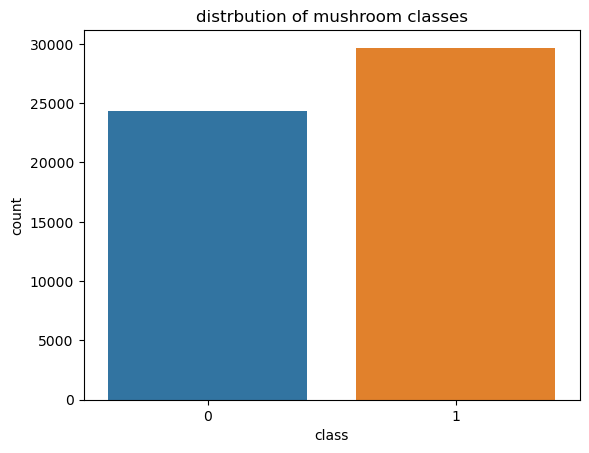

In [22]:
sns.countplot(x='class',data=df)
plt.title('distrbution of mushroom classes')
plt.xlabel('class')
plt.ylabel('count')
plt.show()

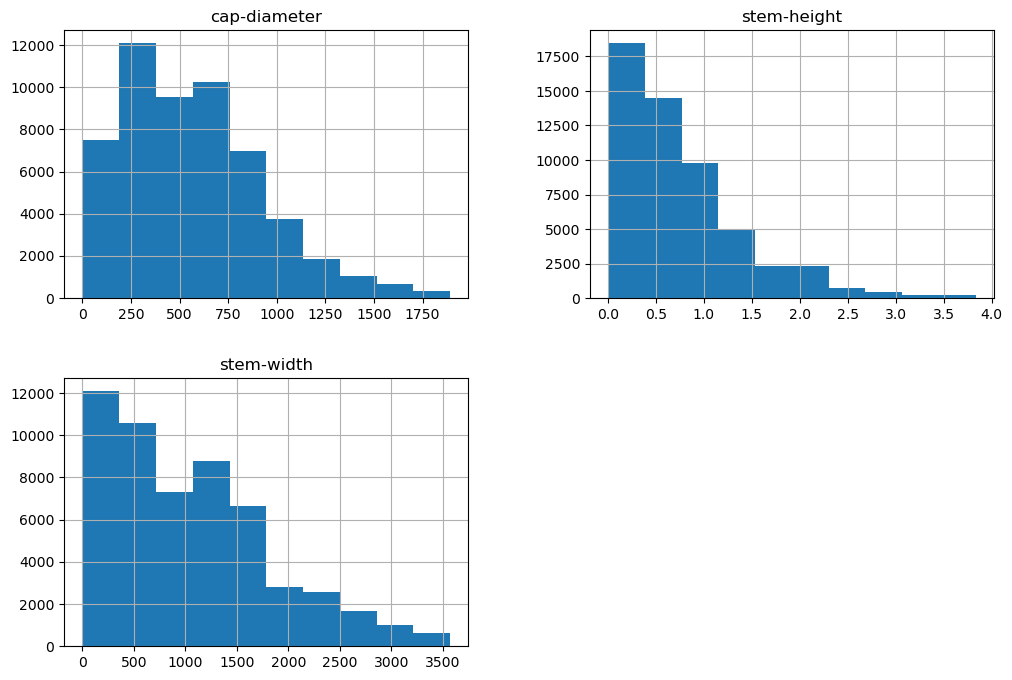

In [24]:
df['class'].value_counts(normalize=True)*100

1    54.918109
0    45.081891
Name: class, dtype: float64

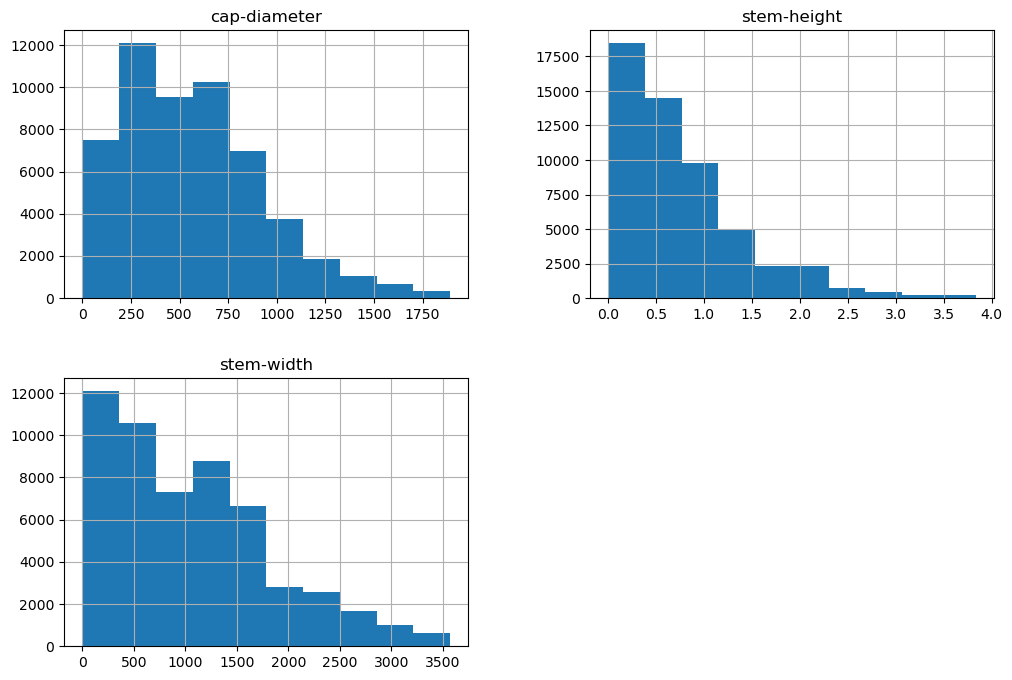

In [25]:
numerical=['cap-diameter','stem-height','stem-width']
df[numerical].hist(figsize=(12,8))
plt.show()

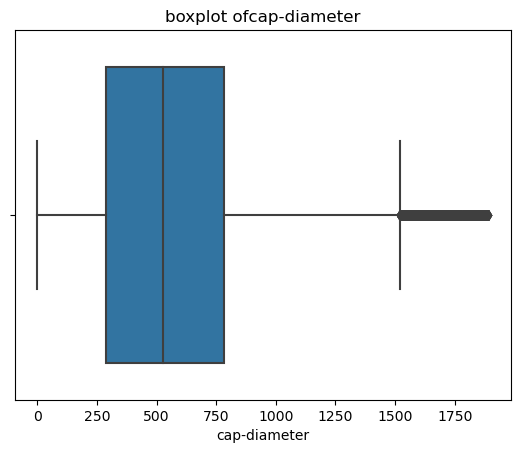

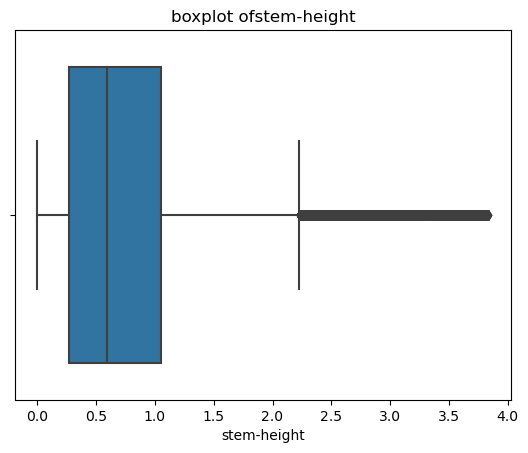

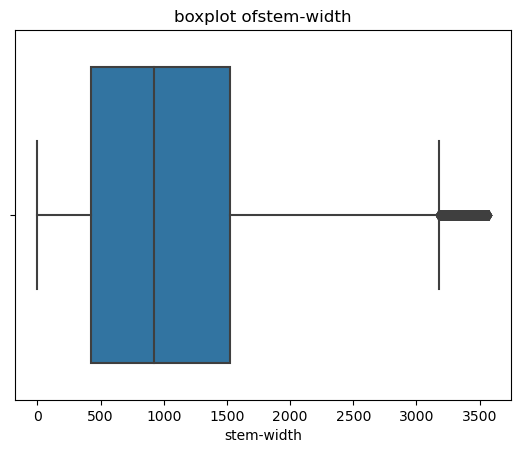

In [26]:
for col in numerical:
    sns.boxplot(data=df ,x=col)
    plt.title(f'boxplot of{col}')
    plt.show()

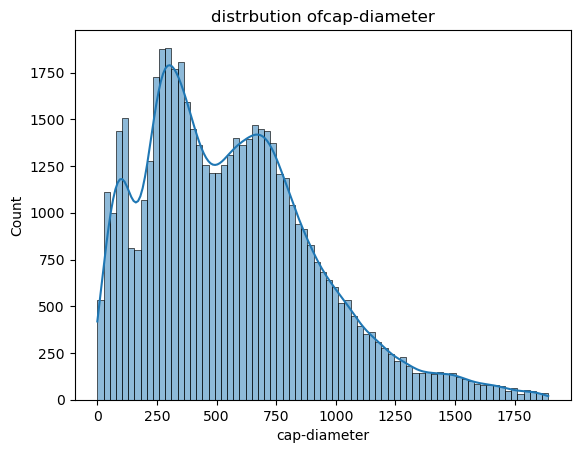

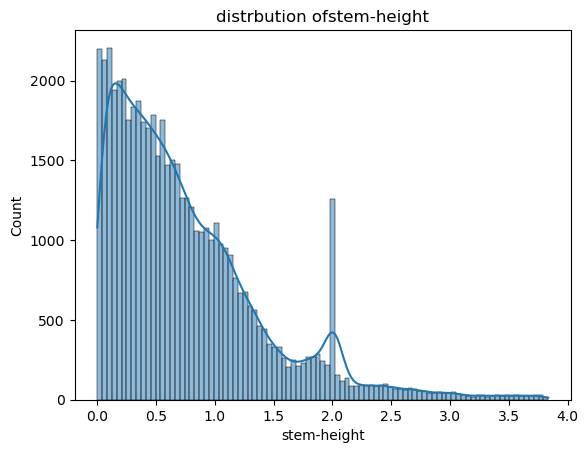

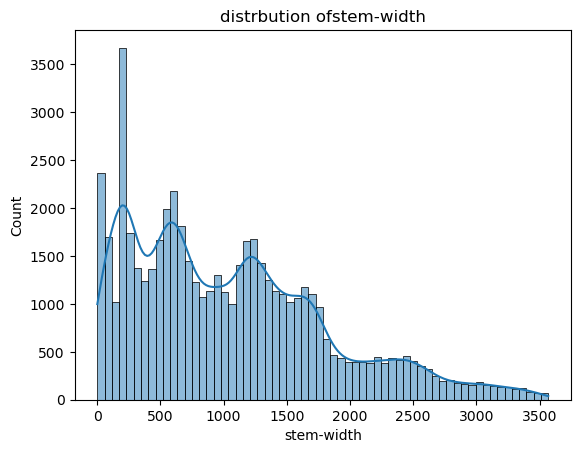

In [27]:
for col in numerical:
    sns.histplot(data=df ,x=col,kde=True)
    plt.title(f'distrbution of{col}')
    plt.show()

In [30]:
categorical=['cap-shape', 'gill-attachment', 'gill-color', 'stem-color','season']

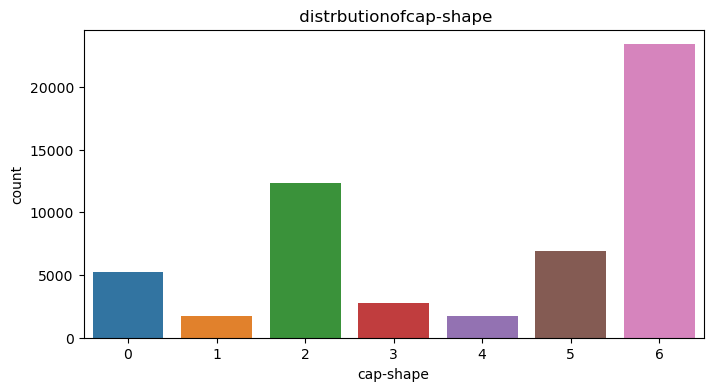

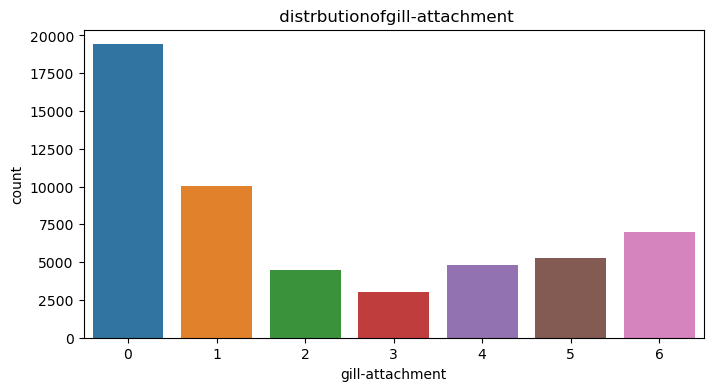

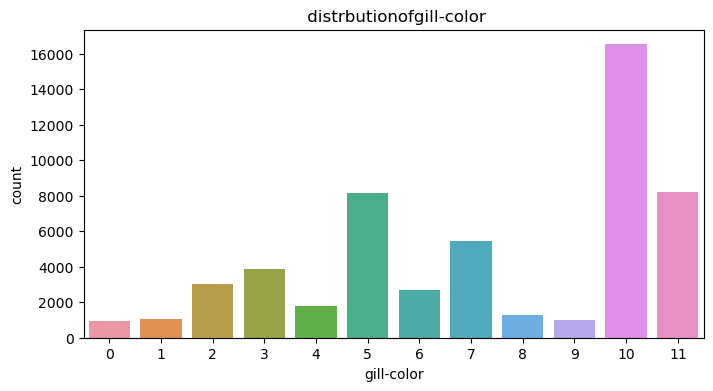

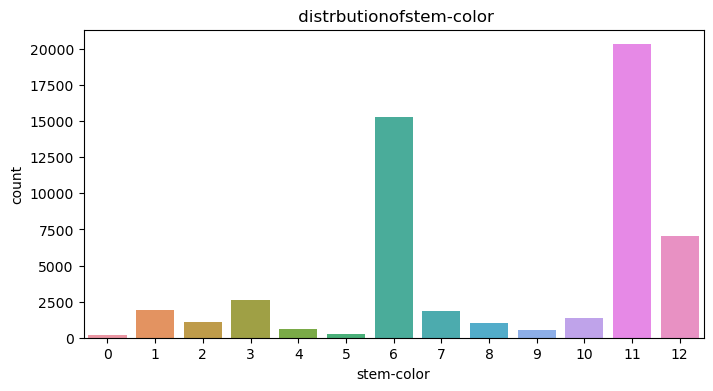

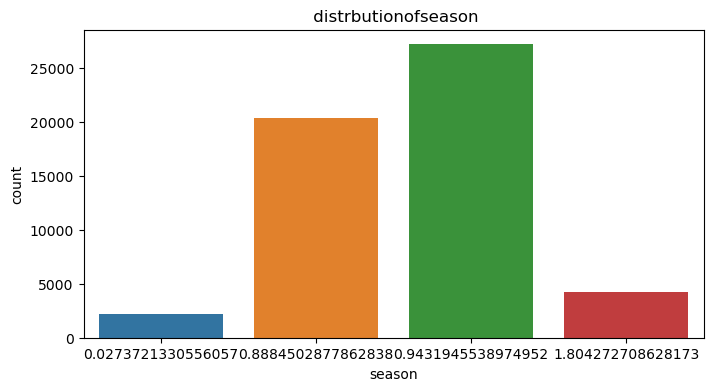

In [32]:
for col in categorical:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df,x=col)
    plt.title(f' distrbutionof{col}')
    plt.show()

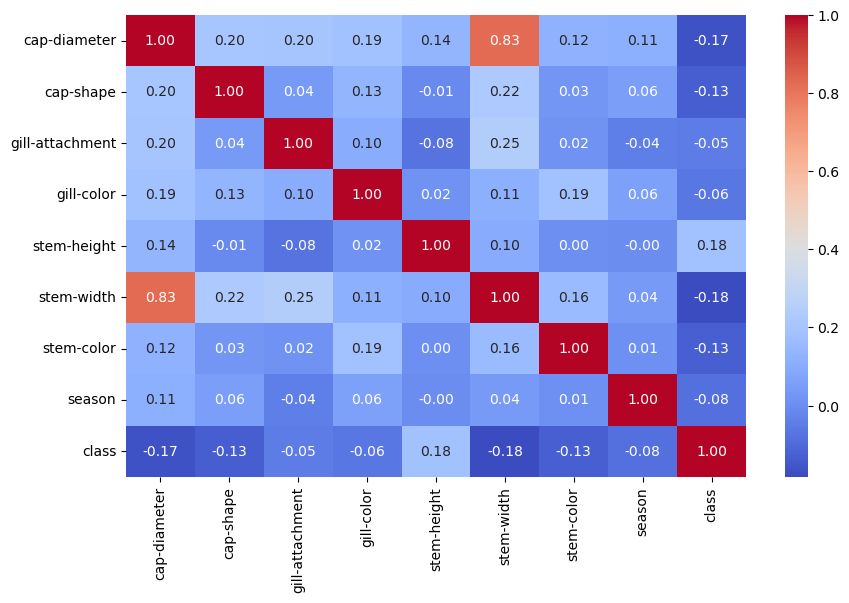

In [34]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True ,cmap='coolwarm' ,fmt='.2f')
plt.show()

In [35]:
x=df.drop(columns=['class'])
y=df['class']

In [36]:
x=pd.get_dummies(x,columns=categorical,drop_first=True)

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [40]:
from sklearn.preprocessing import StandardScaler

In [41]:
scaler=StandardScaler()

In [57]:
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)



In [43]:
df

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1
...,...,...,...,...,...,...,...,...,...
54030,73,5,3,2,0.887740,569,12,0.943195,1
54031,82,2,3,2,1.186164,490,12,0.943195,1
54032,82,5,3,2,0.915593,584,12,0.888450,1
54033,79,2,3,2,1.034963,491,12,0.888450,1


In [45]:
df['class']

0        1
1        1
2        1
3        1
4        1
        ..
54030    1
54031    1
54032    1
54033    1
54034    1
Name: class, Length: 54035, dtype: int64

In [46]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report ,confusion_matrix



In [53]:
lr=LinearRegression()
lr.fit(x_train_scaled,y_train)
y_pred_lr=lr.predict(x_test_scaled)
y_pred_lr_class=(y_pred_lr>=0.5).astype(int)
print("accuracy:",accuracy_score(y_test,y_pred_lr_class))

accuracy: 0.74433237716295


In [55]:
model=LogisticRegression()
model.fit(x_train_scaled,y_train)
y_pred_log=model.predict(x_test_scaled)

print("accuracy:",accuracy_score(y_test,y_pred_log))
print(classification_report(y_test,y_pred_log))

accuracy: 0.7495142037568243
              precision    recall  f1-score   support

           0       0.72      0.72      0.72      4872
           1       0.77      0.77      0.77      5935

    accuracy                           0.75     10807
   macro avg       0.75      0.75      0.75     10807
weighted avg       0.75      0.75      0.75     10807



C:\Users\AHMED\Downloads\Programs\conda\Lib\site-packages\sklearn\linear_model\_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [60]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(x_train_scaled, y_train)

y_pred_knn = knn.predict(x_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print(classification_report(y_test, y_pred_knn))

Accuracy: 0.9888960858702692
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4872
           1       0.99      0.99      0.99      5935

    accuracy                           0.99     10807
   macro avg       0.99      0.99      0.99     10807
weighted avg       0.99      0.99      0.99     10807



In [62]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(x_train, y_train)

y_pred_dt = dt.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print(classification_report(y_test, y_pred_dt))

Accuracy: 0.980290552419728
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      4872
           1       0.98      0.98      0.98      5935

    accuracy                           0.98     10807
   macro avg       0.98      0.98      0.98     10807
weighted avg       0.98      0.98      0.98     10807



In [63]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Logistic Regression',
        'KNN',
        'Decision Tree'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr_class),
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_dt)
    ]
})

results.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
2,KNN,0.988896
3,Decision Tree,0.980291
1,Logistic Regression,0.749514
0,Linear Regression,0.744332
